In [1]:
import pandas as pd 

df = pd.read_csv("customer_churn_cleaned.csv")

print(df.shape)
df.head()

(10000, 16)


,Customer_ID,Gender,Age,Tenure_Months,Contract_Type,Payment_Method,Monthly_Charges,Total_Charges,Internet_Service,Tech_Support,Streaming_Service,Number_of_Complaints,Support_Calls,Last_Login_Days,Satisfaction_Score,Churn
0,C100000,Male,20,62,One Year,Bank Transfer,98.56,6066.68,No Internet,Yes,No,2,0,13,6.4,0
1,C100001,Female,24,4,Month-to-Month,Electronic Check,60.78,232.84,DSL,Yes,No,0,2,25,7.9,1
2,C100002,Female,43,6,Month-to-Month,Electronic Check,103.17,571.54,No Internet,No,Yes,0,5,22,6.3,1
3,C100003,Female,24,72,Month-to-Month,Bank Transfer,68.68,5278.75,DSL,No,Yes,0,2,18,6.1,0
4,C100004,Male,51,16,Month-to-Month,Electronic Check,110.19,1637.33,DSL,No,No,1,3,10,8.2,1


In [2]:
df.isnull().sum()

Customer_ID             0
Gender                  0
Age                     0
Tenure_Months           0
Contract_Type           0
Payment_Method          0
Monthly_Charges         0
Total_Charges           0
Internet_Service        0
Tech_Support            0
Streaming_Service       0
Number_of_Complaints    0
Support_Calls           0
Last_Login_Days         0
Satisfaction_Score      0
Churn                   0
dtype: int64

 Hypothesis 1

In [3]:
from scipy.stats import ttest_ind

churned=df[df['Churn']==1]['Satisfaction_Score'].dropna()
not_churned=df[df['Churn']==0]['Satisfaction_Score'].dropna()

t_stat,p_value=ttest_ind(churned,not_churned,equal_var=False)

print("T-statistic:",t_stat)
print("P-value:",p_value)

T-statistic: -20.05626374268824
P-value: 6.683328856259801e-85


In [4]:
# Calculate the group stastistics

churned = df[df['Churn'] == 1]['Satisfaction_Score'].dropna()
not_churned = df[df['Churn'] == 0]['Satisfaction_Score'].dropna()

print("Churned customers:")
print("Count:", len(churned))
print("Mean:", churned.mean())
print("Standard Deviation:", churned.std())

print("\nNon-churned customers:")
print("Count:", len(not_churned))
print("Mean:", not_churned.mean())
print("Standard Deviation:", not_churned.std())

Churned customers:
Count: 2260
Mean: 6.298672566371682
Standard Deviation: 1.2271634224432053

Non-churned customers:
Count: 7740
Mean: 6.883307493540052
Standard Deviation: 1.1913264591023334


In [5]:
# The difference in mean satisfaction is 0.585 points lower for churned customers compared to non-churned customers.
# The p-value is enough to reject the null hypothesis.
# The t-test results suggest that there is a statistically significant but it doen't mean that the difference is practically large. So,The effect size should be calculated Cohen's d.

import numpy as np

n1 = len(churned)
n2 = len(not_churned)

mean1 = churned.mean()
mean2 = not_churned.mean()

sd1 = churned.std()
sd2 = not_churned.std()

pooled_sd = np.sqrt(
    ((n1 - 1) * sd1**2 + (n2 - 1) * sd2**2)
    / (n1 + n2 - 2)
)

cohens_d = (mean1 - mean2) / pooled_sd

print("Pooled Standard Deviation:", pooled_sd)
print("Cohen's d:", cohens_d)

Pooled Standard Deviation: 1.1995172791281643
Cohen's d: -0.48739183448303103


In [6]:
# Calculate the 95% Confidence Interval
# We are using Welch's t-test 

from scipy.stats import t

mean_difference = churned.mean() - not_churned.mean()

# Welch degrees of freedom
s1 = churned.var(ddof=1)
s2 = not_churned.var(ddof=1)
n1 = len(churned)
n2 = len(not_churned)

se = np.sqrt((s1 / n1) + (s2 / n2))

df_welch = ((s1/n1 + s2/n2)**2) / (
    ((s1/n1)**2 / (n1-1)) +
    ((s2/n2)**2 / (n2-1))
)

critical_value = t.ppf(0.975, df_welch)

ci_lower = mean_difference - critical_value * se
ci_upper = mean_difference + critical_value * se

print("Mean Difference:", mean_difference)
print("Welch Degrees of Freedom:", df_welch)
print("95% Confidence Interval:", (ci_lower, ci_upper))

Mean Difference: -0.58463492716837
Welch Degrees of Freedom: 3593.9093607851673
95% Confidence Interval: (-0.6417866205369638, -0.5274832337997761)


<Figure size 800x600 with 0 Axes>

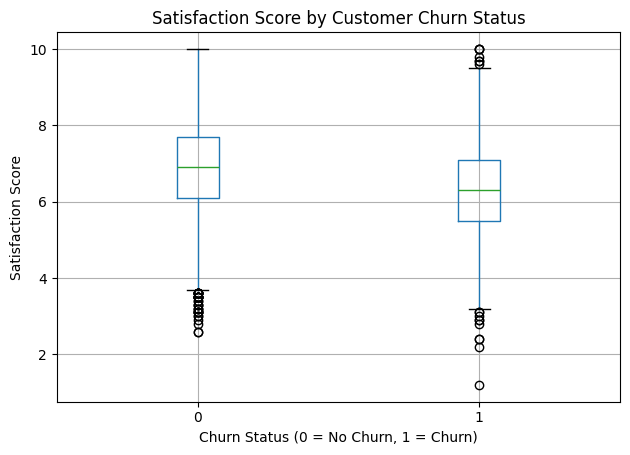

In [7]:
# Visualize the distribution of Satisfaction_Score for churned and non-churned customers

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

df.boxplot(
    column='Satisfaction_Score',
    by='Churn'
)

plt.title('Satisfaction Score by Customer Churn Status')
plt.suptitle('')
plt.xlabel('Churn Status (0 = No Churn, 1 = Churn)')
plt.ylabel('Satisfaction Score')

plt.tight_layout()
plt.savefig(
    "satisfaction_score_by_churn_status.png",
    dpi=300,
    bbox_inches='tight'
)
plt.show()


Hypothesis-2

In [8]:
# Chi-Square Test
# Is customer contract type significantly associated with customer churn?

# Create the contingency table

contingency_table = pd.crosstab(
    df['Contract_Type'],
    df['Churn']
)

print(contingency_table)

Churn              0     1
Contract_Type             
Month-to-Month  3881  1715
One Year        2059   354
Two Year        1800   191


In [9]:
# Calcuate the Chi-Square Test

from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)


Chi-square statistic: 486.44451418365196
Degrees of freedom: 2
P-value: 2.343774737957795e-106


In [10]:
# Check the expected frequencies to ensure they are all greater than 5

print("\nExpected frequencies:")
print(expected)


Expected frequencies:
[[4331.304 1264.696]
 [1867.662  545.338]
 [1541.034  449.966]]


In [11]:
print("Minimum expected frequency:", expected.min())

Minimum expected frequency: 449.966


In [12]:
# The p-value tells us whether an association exists, but it doesn't tell us how strong the association is.
# we will calculate Cramér's V to measure the strength of the association.

n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(contingency_table.shape[0] - 1,
                    contingency_table.shape[1] - 1))
)

print("Cramer's V:", cramers_v)

Cramer's V: 0.22055487167225574


In [13]:

churn_rate = (
    df.groupby('Contract_Type')['Churn']
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

print(churn_rate)

Contract_Type
Month-to-Month    30.646891
One Year          14.670535
Two Year           9.593169
Name: Churn, dtype: float64


In [14]:
contingency_table = pd.crosstab(
    df['Contract_Type'],
    df['Churn']
)

print(contingency_table)

Churn              0     1
Contract_Type             
Month-to-Month  3881  1715
One Year        2059   354
Two Year        1800   191


In [15]:
# Run the Chi-Square Test

from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)


Chi-square statistic: 486.44451418365196
Degrees of freedom: 2
P-value: 2.343774737957795e-106


In [16]:
print("\nExpected frequencies:")
print(expected)

print("\nMinimum expected frequency:", expected.min())


Expected frequencies:
[[4331.304 1264.696]
 [1867.662  545.338]
 [1541.034  449.966]]

Minimum expected frequency: 449.966


In [17]:
# A very small p-value tells us that the relationship is statistically significant, but not whether it is weak, moderate, or strong.
# We will calculate Cramér's V to measure the strength of the association.

import numpy as np

n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (
        n * min(
            contingency_table.shape[0] - 1,
            contingency_table.shape[1] - 1
        )
    )
)

print("Cramer's V:", cramers_v)

# Check the expected frequencies

print("Expected frequencies:")
print(expected)

print("\nMinimum expected frequency:", expected.min())

Cramer's V: 0.22055487167225574
Expected frequencies:
[[4331.304 1264.696]
 [1867.662  545.338]
 [1541.034  449.966]]

Minimum expected frequency: 449.966


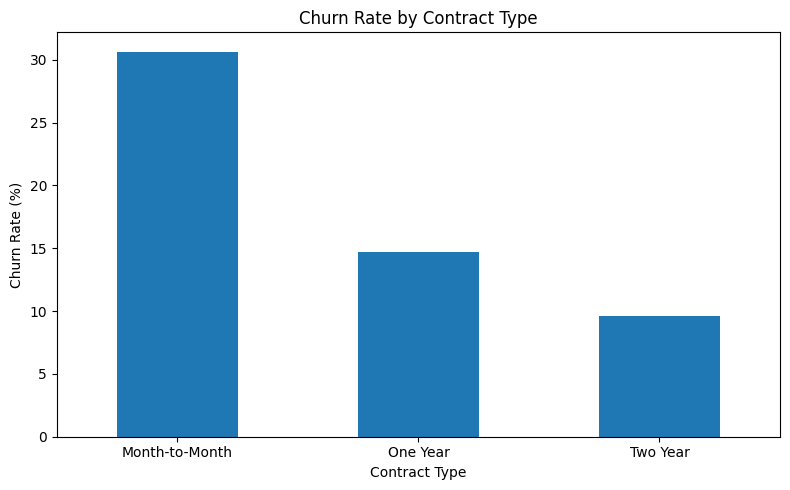

In [18]:
# Visualize the churn rate chart by contract type

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

churn_rate.plot(kind='bar')

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig(
    "churn_rate_by_contract_type.png",
    dpi=300,
    bbox_inches='tight'
)
plt.show()

Hypothesis-3

In [19]:
# ANOVA Test : Satisfaction_Score across different Contract_Type categories
# Does the average customer satisfaction score differ significantly across the three contract types?

# Calcuate the group statistics

df.groupby('Contract_Type')['Satisfaction_Score'].agg(
    ['count', 'mean', 'std'] )

,count,mean,std
Contract_Type,,,
Month-to-Month,5596,6.730164,1.215658
One Year,2413,6.785454,1.240015
Two Year,1991,6.768709,1.227880


In [20]:
# The means are very close to each other,contract type has a strong association with churn but not with satisfaction score. 
# We need to test whether these small differences are statistically significant.

# Levene's Test

from scipy.stats import levene

month_to_month = df[
    df['Contract_Type'] == 'Month-to-Month'
]['Satisfaction_Score'].dropna()

one_year = df[
    df['Contract_Type'] == 'One Year'
]['Satisfaction_Score'].dropna()

two_year = df[
    df['Contract_Type'] == 'Two Year'
]['Satisfaction_Score'].dropna()

levene_stat, levene_p = levene(
    month_to_month,
    one_year,
    two_year
)

print("Levene statistic:", levene_stat)
print("Levene p-value:", levene_p)

Levene statistic: 0.8744404675285471
Levene p-value: 0.4171272328896478


In [21]:
# We fail to reject the null hypothesis of equal variances, so we can proceed with the Standard One-Way ANOVA test. 

# Run One-Way ANOVA

from scipy.stats import f_oneway

f_stat, p_value = f_oneway(
    month_to_month,
    one_year,
    two_year
)

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 1.974975103950405
P-value: 0.1388189050040559


<Figure size 800x600 with 0 Axes>

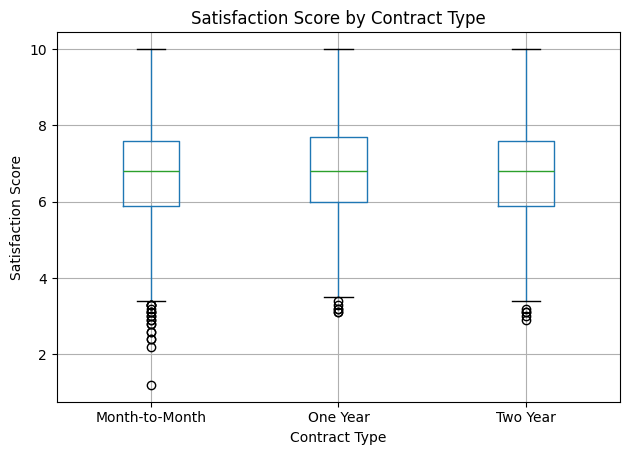

In [22]:
# Visualize the distribution of Satisfaction_Score by Contract type.


import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

df.boxplot(
    column='Satisfaction_Score',
    by='Contract_Type'
)

plt.title('Satisfaction Score by Contract Type')
plt.suptitle('')
plt.xlabel('Contract Type')
plt.ylabel('Satisfaction Score')
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig(
    "Satisfaction Score by Contract Type.png",
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [22]:
# We calculate the effect size using eta-squared (η²) to quantify the proportion of variance in Satisfaction_Score that can be attributed to Contract_Type.

import pandas as pd
import numpy as np

# Define the three contract groups
month_to_month = df[
    df['Contract_Type'] == 'Month-to-Month'
]['Satisfaction_Score'].dropna()

one_year = df[
    df['Contract_Type'] == 'One Year'
]['Satisfaction_Score'].dropna()

two_year = df[
    df['Contract_Type'] == 'Two Year'
]['Satisfaction_Score'].dropna()

# Combine the groups
groups = [month_to_month, one_year, two_year]

all_scores = pd.concat(groups)
grand_mean = all_scores.mean()

# Calculate between-group variation
ss_between = sum(
    len(group) * (group.mean() - grand_mean) ** 2
    for group in groups
)

# Calculate total variation
ss_total = ((all_scores - grand_mean) ** 2).sum()

# Calculate eta-squared
eta_squared = ss_between / ss_total

print("Eta-squared:", eta_squared)
print(
    "Percentage of variation explained:",
    round(eta_squared * 100, 4), "%"
)

Eta-squared: 0.00039495750179398986
Percentage of variation explained: 0.0395 %


In [23]:
# Final statistical-quality check 
# Summary of all three hypothesis tests

import pandas as pd

results = pd.DataFrame({
    "Hypothesis": [
        "Satisfaction Score vs Churn",
        "Contract Type vs Churn",
        "Satisfaction Score vs Contract Type"
    ],
    "Statistical_Test": [
        "Welch's Independent T-Test",
        "Chi-Square Test",
        "One-Way ANOVA"
    ],
    "Test_Statistic": [
        -20.0563,
        486.4445,
        1.9750
    ],
    "P_Value": [
        6.683328856259801e-85,
        2.343774737957795e-106,
        0.1388189050040559
    ],
    "Decision": [
        "Reject H0",
        "Reject H0",
        "Fail to Reject H0"
    ]
})

print(results.to_string(index=False))

                         Hypothesis           Statistical_Test  Test_Statistic       P_Value          Decision
        Satisfaction Score vs Churn Welch's Independent T-Test        -20.0563  6.683329e-85         Reject H0
             Contract Type vs Churn            Chi-Square Test        486.4445 2.343775e-106         Reject H0
Satisfaction Score vs Contract Type              One-Way ANOVA          1.9750  1.388189e-01 Fail to Reject H0
